# Whisper Model for Speech Recognition

In this Jupyter Notebook is documented exploration and analysis of the `Whisper` model used for speech recognition. This document contains introduction to the audio clips used for testing, their mel-spectrograms, testing and analysis of the different Whisper model versions and final conclusions. The `MarianMTModel` model used for translations was also tested as a bonus. The models are obtained with the `transformers` library.

The Whisper model is built with `PyTorch` as its backend, so the `torch` library needs to be imported. The `librosa` library is used for handling, transforming and visually displaying audio along with the `Audio` class and `display` function from `IPython.display` library. The `numpy` library makes it simpler to handle and reshape the data, and the `matplotlib.pyplot` library provides functions for visualising data.

In [1]:
import re
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import (WhisperProcessor, WhisperForConditionalGeneration,
                          MarianMTModel, MarianTokenizer)

# pip install transformers librosa ipywidgets sentencepiece sacremoses

## Audio Clips (Riikka)

Eight audio clips of different quality and with different quirks were chosen to test the Whisper model's ability to recognise speech. The clips were recorded with the `Audacity` application and all but one were saved as wav-files. One was saved as an aiff-file. Each clip contains around 15 to 26 seconds of speech. There are four different speakers in total in these clips: the four team members and a family member. The clips are numbered to set them in order and to make referencing them simpler. The numbers are part of the filename.

- The first clip contains clear, well enunciated speech to set the starting point and baseline for comparisons. The speaker in the first clip describes the cold and rainy autumn weather and the warm and cozy indoors.
  
- The second and third have different speakers but the same script is read. These two clips can be used to analyse how different speakers and the changes to the audio colour might affect the model's ability to recognize speech. In these clips the speakers describe the smell of coffee and tell how it has more complex aroma compound than a glass of wine.
  
- The fourth and fifth clips use the same coffee script but contain manually made noise and muddling making the audio quite messy and unclear. The noises were made by crunching some plastic wrapper in front of the mic. These clips can be used to test the model's ability to handle low quality and to recognize words from messy audio.

- The coffee script was also used in the sixth clip. A recording of some rain, found from the archived [YLE Tehosto site](https://vintti.yle.fi/yle.fi/tehosto.yle.fi/tehostelista.html), was added to the speech recording to add a more constant background noise. This clip can also be used to test the model's ability to recognize speech from messy audio.

- The seventh clip contains speech spoken with a Finnish dialect different from the standard Finnish written language. This clip can be used to test the model's ability to recognize non-standard Finnish words and accents.

- The eight clip contains some speech in English, to test the model's ability to handle speech in another language when the model is set to recognize Finnish. The speaker in the clip describes their typical winter day routine.

The clips can be listened from below by clicking the play buttons. Each clip has statistic printed underneath it showing the length and sampling rate of the clip.

In [2]:
import os

audio_data = "datasets/audio_clips/in_use"
audio_files = os.listdir(audio_data)
#audio_files = ["syksy.wav", "anni_kahvi.wav", "riikka_kahvi_v4.wav", "riikka_kahvi_sotkuinen.wav", "taustahäly_audio.aiff", "taustahälyä_koneoppiminen_v2.wav"]

file_data = []

for file_name in audio_files:
    file = f"{audio_data}/{file_name}"
    
    # Load audio file
    y, sr = librosa.load(file, sr=16000) # Lisää audion arvot ja sampling rate monikkona listaan
    file_data.append((y, sr))

    # Display audio for playback
    print("\033[1m" + f"\nFilename: {file_name}" + "\033[0m")
    print("Play the audio:")
    display(Audio(y, rate=sr))

    # Print audio statistics
    duration = librosa.get_duration(y=y, sr=sr)
    print(f"Audio Statistics:")
    print(f"Duration: {duration:.2f} seconds")
    print(f"Sample rate: {sr} Hz\n")


Filename: 1_sandra_syksy.wav
Play the audio:


Audio Statistics:
Duration: 14.91 seconds
Sample rate: 16000 Hz


Filename: 2_anni_kahvi.wav
Play the audio:


Audio Statistics:
Duration: 22.64 seconds
Sample rate: 16000 Hz


Filename: 3_riikka_kahvi_v4.wav
Play the audio:


Audio Statistics:
Duration: 19.51 seconds
Sample rate: 16000 Hz


Filename: 4_nur_kahvi_taustahaly.aiff
Play the audio:


Audio Statistics:
Duration: 26.25 seconds
Sample rate: 16000 Hz


Filename: 5_riikka_kahvi_sotkuinen.wav
Play the audio:


Audio Statistics:
Duration: 20.48 seconds
Sample rate: 16000 Hz


Filename: 6_riikka_taustahälyä_koneoppiminen_v2.wav
Play the audio:


Audio Statistics:
Duration: 20.18 seconds
Sample rate: 16000 Hz


Filename: sandra_winter_english.wav
Play the audio:


Audio Statistics:
Duration: 16.47 seconds
Sample rate: 16000 Hz



## Spectograms (Riikka)

The Whisper model uses audio data as `mel spectograms`. Mel spectogram displays the audio scaling the frequencies to resemble the way humans hear sounds and pitch. In mel spectograms the frequencies do not have a standard spacing. Instead, the lower frequencies, that humans are better at distinguishing, have a wider spacing and the higher frequencies are more densely spaced, since humans cannot hear them well. When an audio is visually displayed as a mel spectogram, the x-axis represents the `time` in seconds and the y-axis represents the `frequency` in hertz. The spectogram is also a type of heat map. The lighter the colour, the louder the sound. Darker colours mean quieter sounds, and black signals the absence of any sound. The loudness is measured with `decibels`.

The audio clips are transformed into a mel spectograms before they are given for the Whisper model since the model cannot properly handle raw audio data for speech recognition. The mel spectogram makes it easier for the model to recognize human speech which is the purpose of the model. In mel spectogram, the data consists of timeframes, and each timeframe has a vector presentation of frequency values. Whisper models are `transformers`, like the generative text model in part one of this project assignment. They both use `embeddings` to represent single values in a more complex and informative form. While the generative text model only consists of a `decoder` transformer block, the Whisper model also has an `encoder` transformer block. The Whisper model takes the mel spectogram of the audio as an input, refines the timeframe frequency embeddings, or encodes them, into vectors with more information and context and transforms, or decodes, them into text by predicting suitable tokens based on the encoded vectors. 

Below is displayed the waveforms and mel spectograms for each of the audio clips.

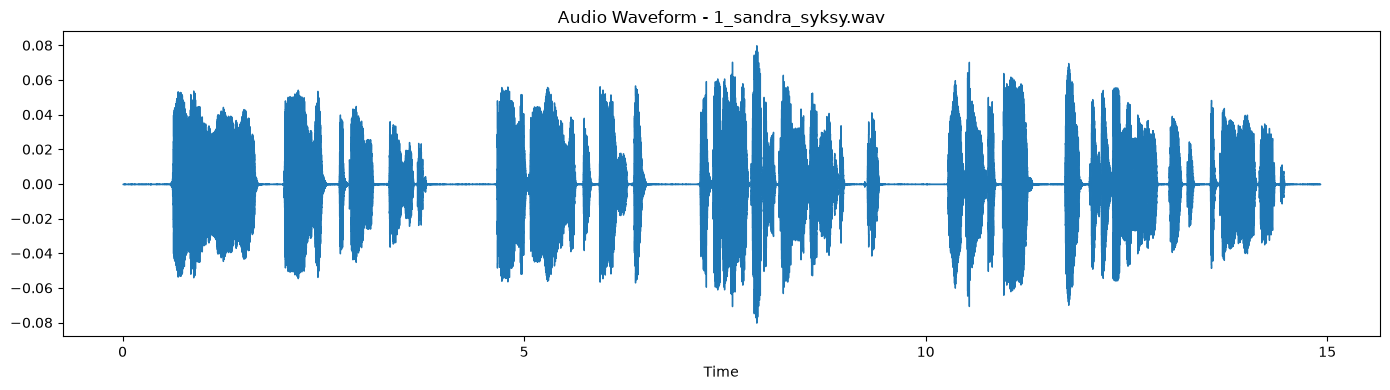

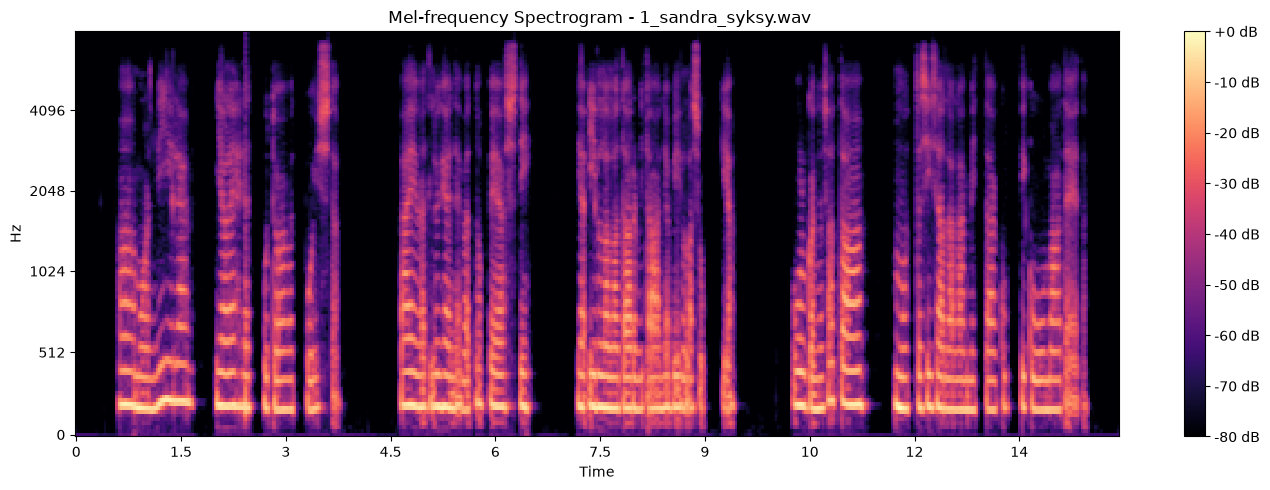




--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------





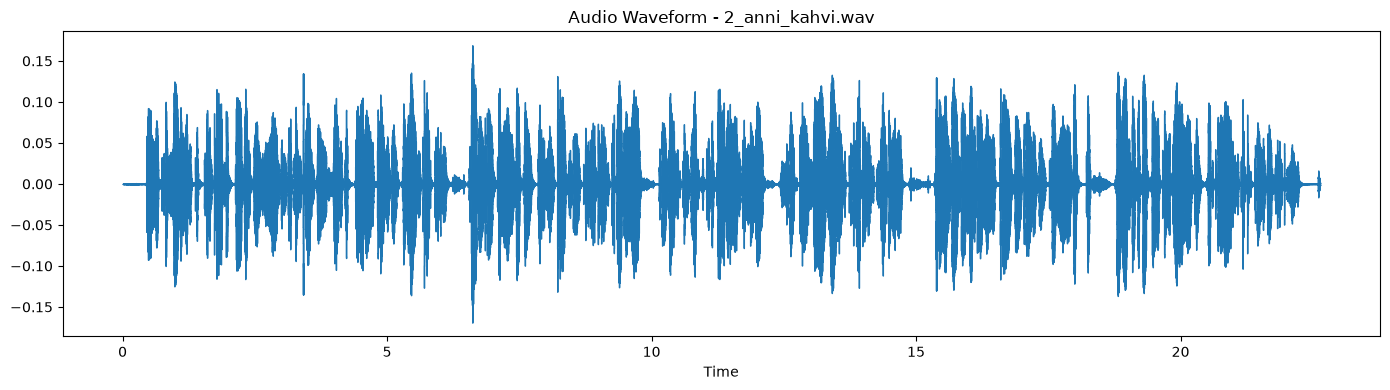

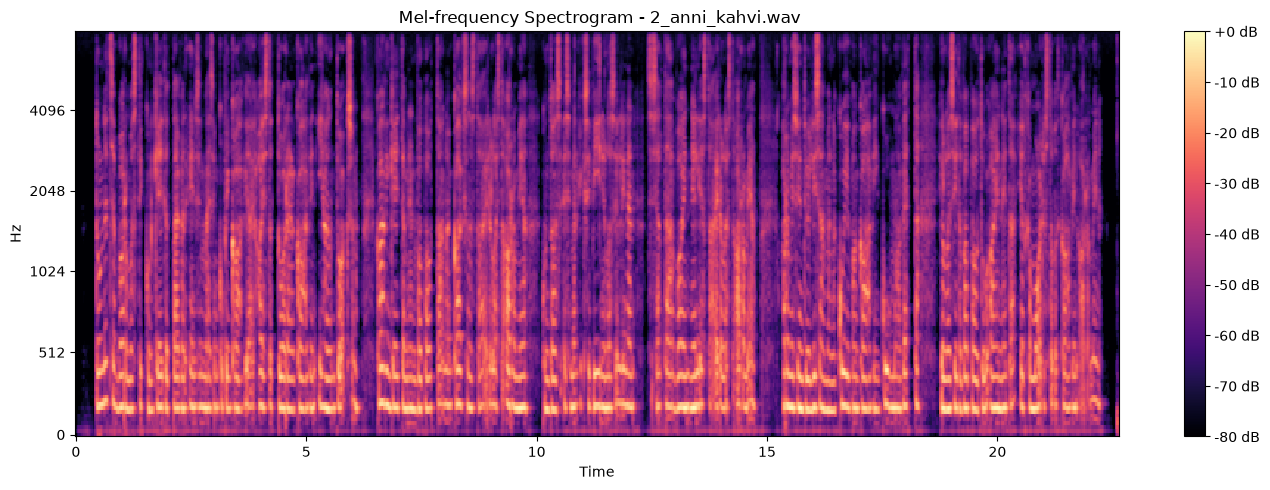




--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------





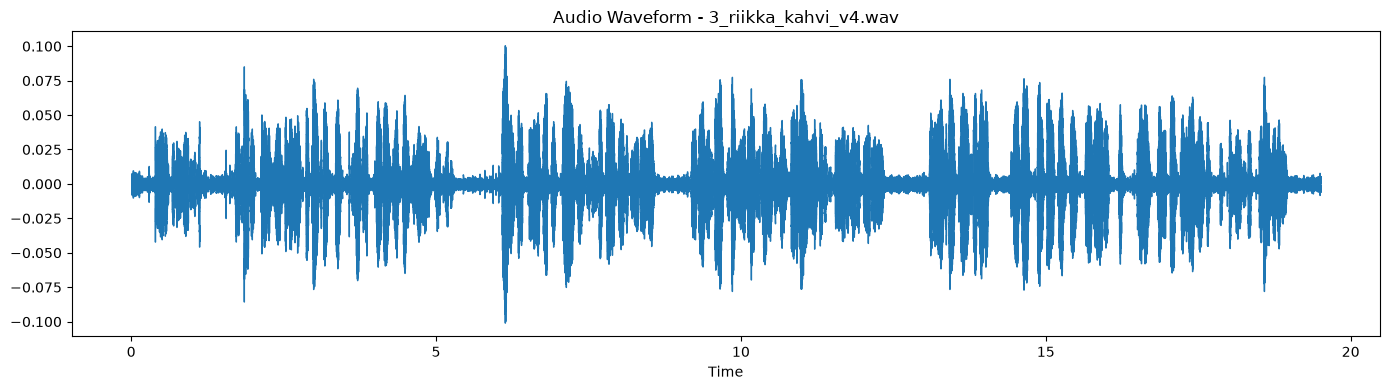

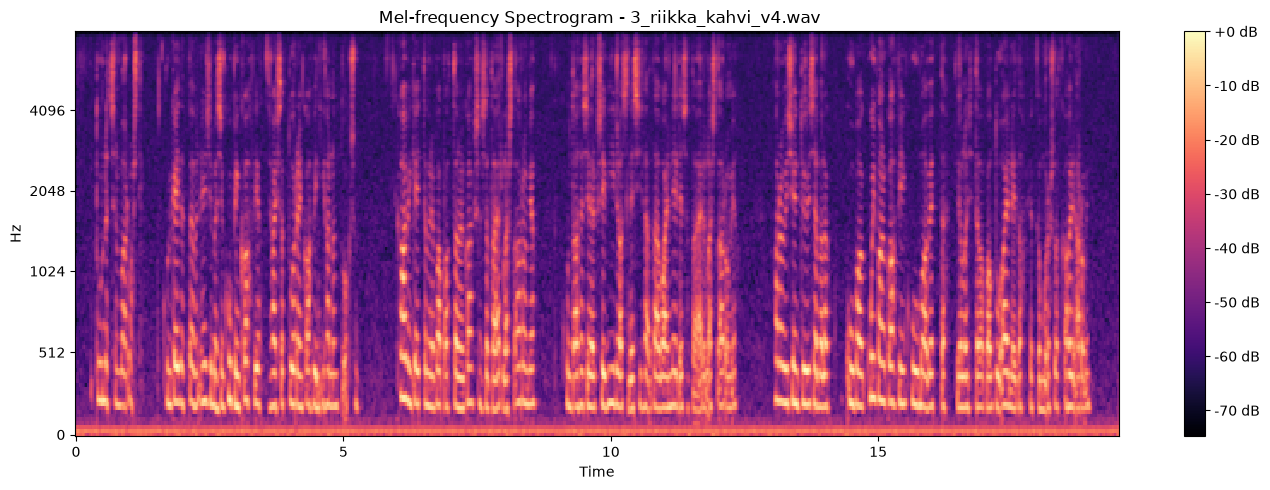




--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------





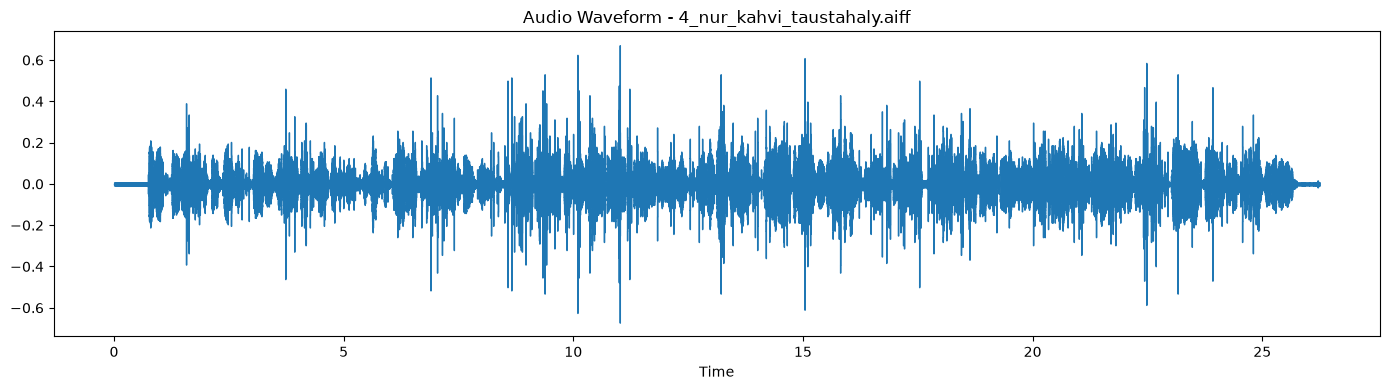

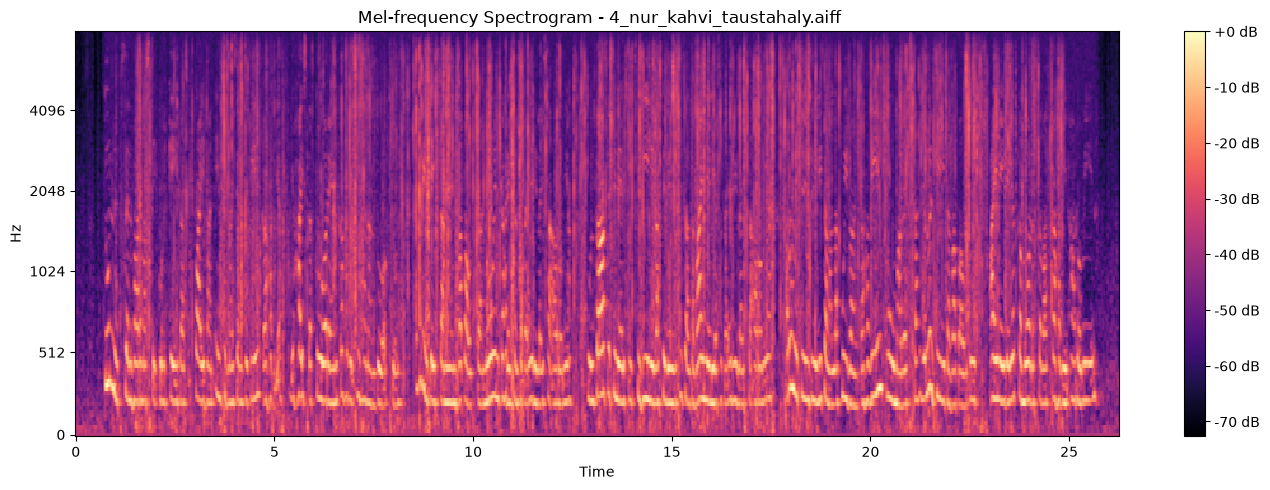




--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------





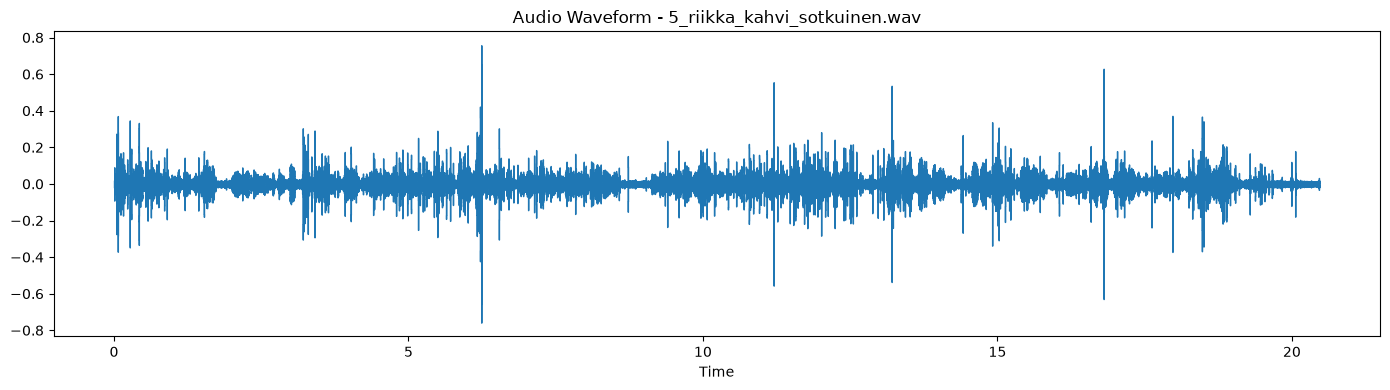

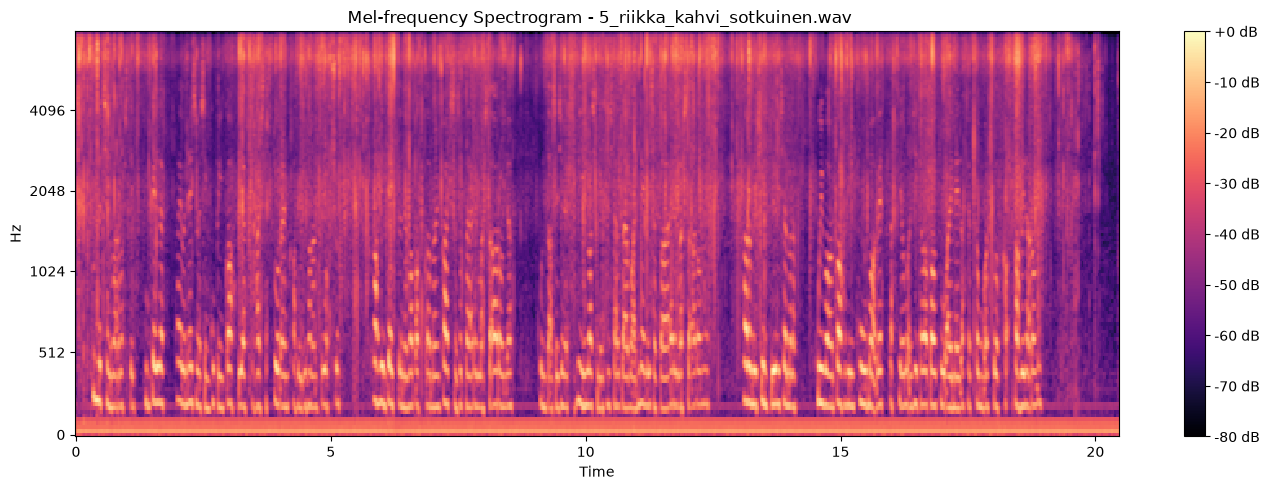




--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------





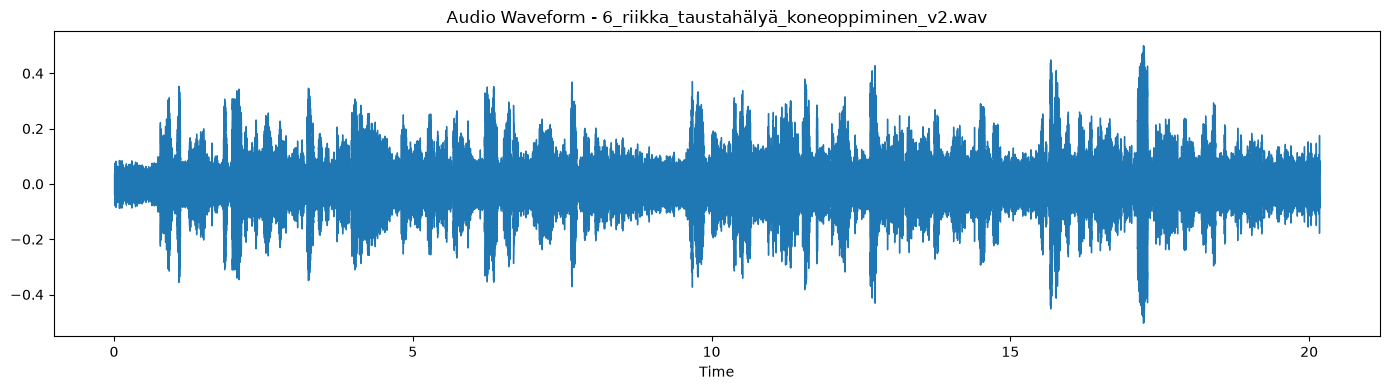

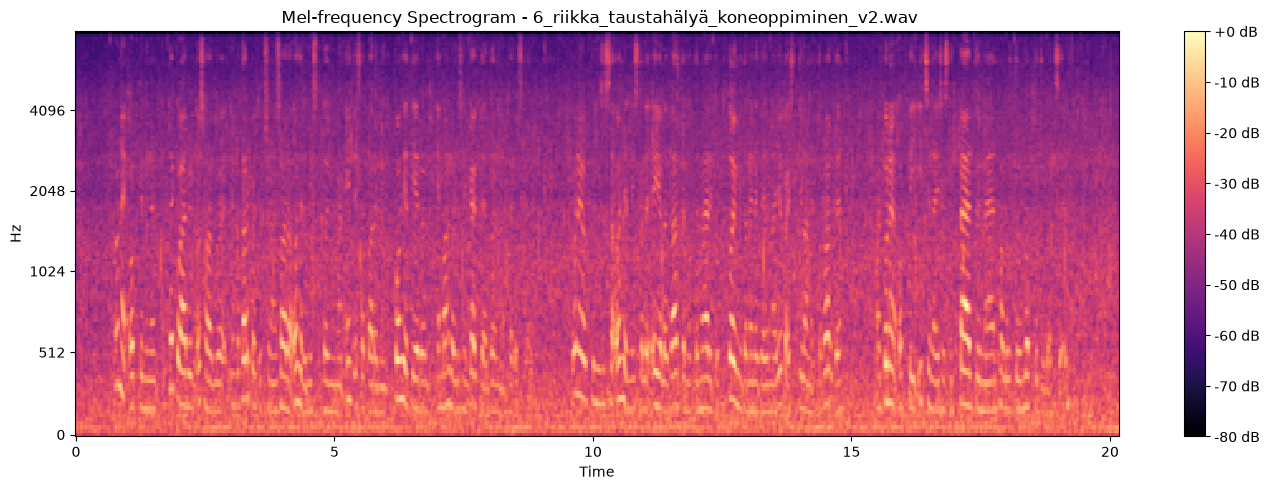




--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------





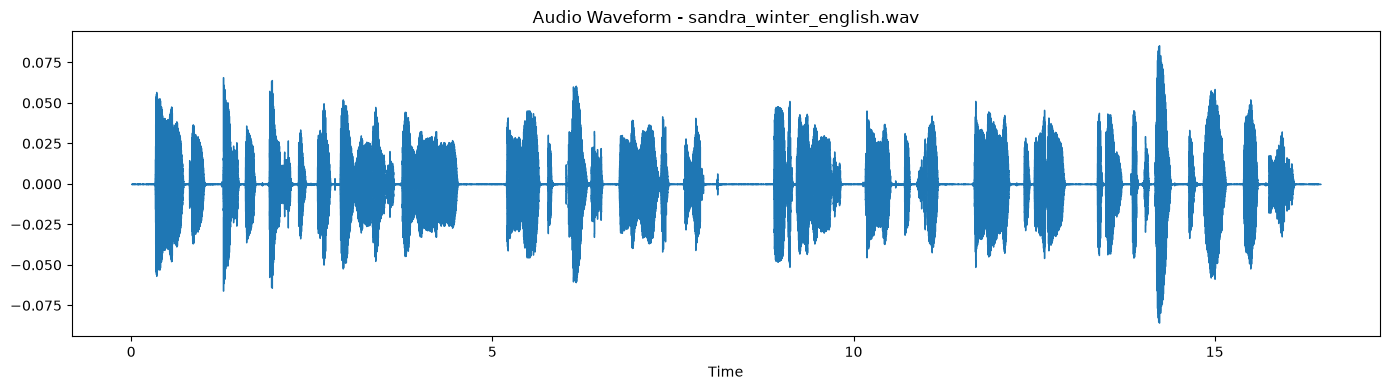

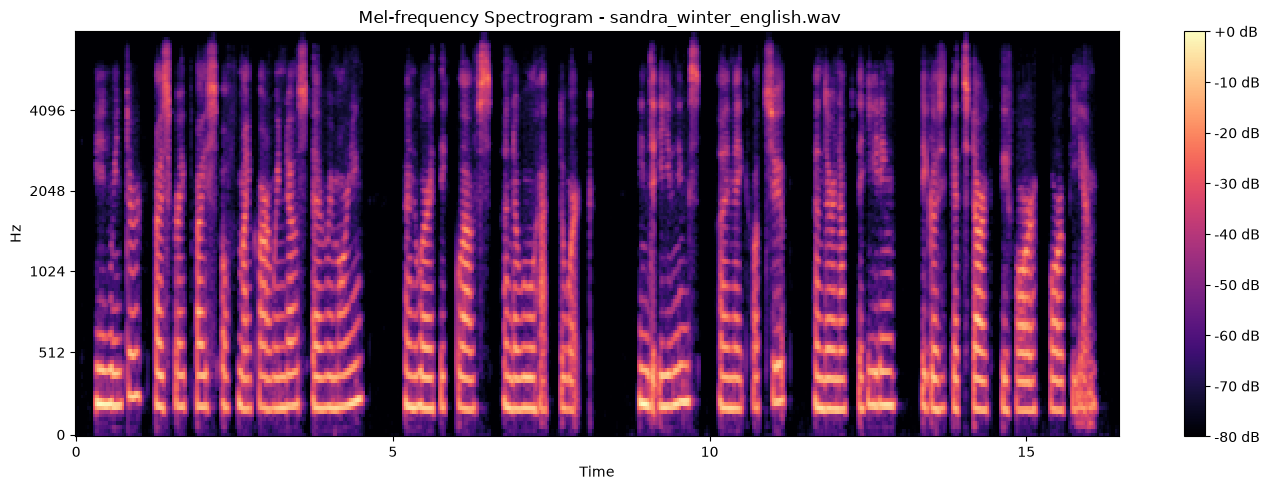




--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------





In [3]:
count = 0
for data in file_data:
    
    # Plot waveform
    plt.figure(figsize=(14, 4))
    librosa.display.waveshow(data[0], sr=data[1])
    plt.title(f'Audio Waveform - {audio_files[count]}')
    plt.tight_layout()
    plt.show()

    # Create mel spectrogram
    plt.figure(figsize=(14, 5))
    S = librosa.feature.melspectrogram(y=data[0], sr=data[1], n_mels=128) # audio[0] = y eli ääniaallon arvot, audio[1] = sr eli sampling rate
    S_dB = librosa.power_to_db(S, ref=np.max)
    librosa.display.specshow(S_dB, y_axis='mel', x_axis='time', sr=sr)
    plt.colorbar(format='%+2.0f dB')
    plt.title(f' Mel-frequency Spectrogram - {audio_files[count]}')
    plt.tight_layout()
    plt.show()

    count += 1
    print("\n\n\n" + ("-" * 200) + "\n\n\n")

Analysing the spectograms provides us some interesting observations. Speech produces these horizontal wavering light lines especially in lower frequencies. 

In the first and the last spectograms, pauses between words are clearly noticeable as black empty spaces since there is no sound. These two clips are overall really clear as there seems to be no background noise of any sort. Compare these two to the second and third spectograms. They have some background noise since, while the pauses between words are still identifieable, they are not as dark as in the first and last spectograms.

It the second and third audio clips, the same text was read but by two different people. This produces two different spectograms with noticeably different presentations. In the third spectogram, the pauses between words are slightly more pronounced than in the second spectogram. It is hard for a human eye to see distinctly similar patterns between these two spectograms. 

In the fourth and fifth spectograms, there is more disturbance. There is noticeable sound even during pauses between words, and some of the sound disturbance on the higher frequency is quite loud indicated by lighter colours. Especially in the fifth spectogram there is clear disturbance on the higher frequencies throughout the whole time. Unclear audio, and mel spectograms, might make it hard for the model to recognise speech correctly.

The sixth spectogram has also a lot of disturbance, though it is quite different. The added rain recording can be seen as the constant static, and it blurries the pauses and other clear changes in frequnecies and loudness that are noticeable in other spectograms. The light horizontal speech pattern lines are still recognisable in the lower frequnecies.

It is also worth noting the horizontal rectangle formed in the very low frequnecies in the third and fifth spectograms. This might have been caused by the noise made by computer cooling fans during the recording. The noise is constant and unchanging throughout the whole audio clip, so it is not related to speech. This is only a theory and the actual cause could be something else.

## Whisper Model - Versions (Nur)

En jaksanut vielä ajaa tätä uudestaan tässä repon omassa versiossa, kun se kestää ainakin mun koneella suhteellisen kauan. Tulosteilla siis on alla vanhat tiedostonimet ja ne ei ole oikeassa järjestyksessä. Täytyy ajaa uudestaan viimeistään siinä vaiheessa, kun saadaan puuttuvat äänitteet. -Riikka

In [18]:
# Valitse laite: NVIDIA-GPU, Apple-GPU tai CPU
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print(f"Using device: {device}")

versions = ["tiny", "base", "small", "medium", "large-v3"]
best_transcriptions = []

count = 0
for audio in file_data:
    print("\033[1m" + f"\n{audio_files[count]}" + "\033[0m")
    for version in versions:
        print(f"\n{version}:")
        model_name = f"openai/whisper-{version}"   # vaihtoehtoja: tiny, base, small, medium, large-v3
        processor = WhisperProcessor.from_pretrained(model_name)
        model = WhisperForConditionalGeneration.from_pretrained(model_name).to(device)

        # Koko äänite kerralla (truncation=False): Whisper käsittelee 30 s pätkissä ja
        # ilman tätä yli 30 s pitkä ääni katkeaisi.
        # audio[0] = y ja audio[1] = sr. 
        # Muutetaan mel spektogrammiksi prosessorin avulla
        inputs = processor(audio[0], sampling_rate=audio[1], return_tensors="pt",
                           truncation=False, padding="longest",
                           return_attention_mask=True).to(device, model.dtype)

        with torch.no_grad():
            generated_ids = model.generate(**inputs, language="fi", task="transcribe",
                                           return_timestamps=True)   # pakollinen yli 30 s äänelle

        transcription = processor.batch_decode(
            generated_ids, skip_special_tokens=True,
            clean_up_tokenization_spaces=False)[0].strip()

        print("FINNISH TRANSCRIPTION:")
        print("=" * 50)
        print(transcription)
        if version == "large-v3":
            best_transcriptions.append(transcription)
    count += 1
    print("\n" + ("#" * 228) + "\n\n")

Using device: cpu

anni_kahvi.wav

tiny:


Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

FINNISH TRANSCRIPTION:
Tuntitse varmasti kun kehitetään, että ensimmäisen kupinkaa viai haistattuoren kahvin ihan on toksen. Kavin kehittäminen vapauttaa, että kaksana sitä erilasta aromia, kun tosi esimerkiksi viinilasellinen, sisältää voin neljasta erilasta armiä. Armi sientyy lisäämänä kuivan kahvin kuumaan vettä, jolla siitä vapautuu aineita, jotka muodostavat kahvin armin.

base:


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

FINNISH TRANSCRIPTION:
Tunnetse varmasti kun keitot tai vähensimmäisen kupinkahviai haistat tuoreen kahvin ihanan tuokson. Kahvin keittäminen vapauttaan on kahdeksonasta aeromia, kun taas esimerkiksi viinilasellinen sisältää vain neljestä aeromia. Aeromi syntyvät lisäämällä kuivan kahvin kuumaan vettä, jolloin siitä vapautuu aineita, jotka muodostavat kahvin aeromin.

small:


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

... (51 outputs left out)

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

FINNISH TRANSCRIPTION:
Koneoppiminen on tekoälyn osa-alue, jonka tarkoituksena on saada ohjelmista toimimaan entistä paremmin kohjatiedon ja mahdolliseen käyttäjän toimimaan peruskelle. Koneoppimisessa ohjelmistolle ei ole välttämättä määrittyä toimintameneetelmää jokaista tilannetta varten, vaan koneoppii itsenäisesti päätymään haluttuun loppitulokseen.

large-v3:


Loading weights:   0%|          | 0/1259 [00:01<?, ?it/s]

FINNISH TRANSCRIPTION:
Koneoppiminen on tekoälyn osa-alue, jonka tarkoituksena on saada ohjelmisto toimimaan entistä paremmin pohjatiedon ja mahdollisen käyttäjän toiminnan perusteella. Koneoppimisessa ohjelmistolle ei ole välttämättä määritetty toimintamenetelmä jokaista tilannetta varten, vaan kone oppii itsenäisesti päätymään haluttuun lopputulokseen.

######################################################################################################################################################################################################################################




- Vertailu eri mallien välillä (tarkkuus, nopeus, virheet)
- Analyysi tilanteista, joissa malli onnistuu ja epäonnistuu

Ajatuksia:
- Pienemmät malli pärjäävät suhteellisen hyvin selkeillä äänitteillä.
- Taustahälyä ja sotkua sisältävät äänitteet vaativat suurempia (medium tai large) malleja, jotta puhe tunnistetaan oikein.
- Medium ja large-v3 ovat aika hitaita
- Tiny ja base mallit ovat nopeita
- Small vaatii hiukan enemmän aikaa kuin tiny ja base, mutta on huomattavasti nopeampi kuin medium ja large-v3

## Bonus: English Translations (Nur)

Vain large-v3 version tuottamien tekstien englanninkieliset käännökset (ei tarvitse varmaan kovinkaan paljon tästä kertoa?)
- Onko kahvi-aiheisten transkritioiden käännöksissä eroa? Jos on, miksi (huono äänitelaatu --> virheitä --> ei voida kääntää oikein)?
- Onnistuiko muiden kääntäminen hyvin?

In [22]:
count = 0
for transcription in best_transcriptions:

    print("\033[1m" + f"\n{audio_files[count]}" + "\033[0m")
    # Suomi -> englanti erillisellä käännösmallilla (Whisperin oma "translate" on huono suomelle).
    # Käännetään lause kerrallaan, muuten pitkä teksti katkeaa.
    mt_name = "Helsinki-NLP/opus-mt-fi-en"
    mt_tokenizer = MarianTokenizer.from_pretrained(mt_name)
    mt_model = MarianMTModel.from_pretrained(mt_name)

    sentences = re.split(r"(?<=[.?!])\s+", transcription)
    batch = mt_tokenizer(sentences, return_tensors="pt", padding=True)
    with torch.no_grad():
        out = mt_model.generate(**batch)
    translation = " ".join(mt_tokenizer.batch_decode(out, skip_special_tokens=True))

    print("ENGLISH TRANSLATION:")
    print("=" * 50)
    print(translation)
    print()
    count += 1


anni_kahvi.wav


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

ENGLISH TRANSLATION:
I'm sure you'll feel it when you make the first cup of coffee of the day and smell the sweet smell of fresh coffee. Cooking coffee releases about 800 different flavors, while for example a glass of wine contains only 400 different flavors. The aroma is produced by adding hot water to the dry coffee, releasing substances that form the aroma of coffee.


riikka_kahvi_sotkuinen.wav


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

ENGLISH TRANSLATION:
I'm sure you'll feel it when you bowl the first cup of coffee of the day and damage the sweet smell of fresh coffee. Cooking coffee frees about 800 different flavors, while, for example, the gullet contains only 400 different flavors. The aroma is produced by adding hot water to the dry coffee, releasing substances that form the aroma of coffee.


riikka_kahvi_v4.wav


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

ENGLISH TRANSLATION:
I'm sure you'll feel it when you have the first shot of coffee of the day and smell the sweet smell of fresh coffee. Cooking coffee releases about 800 different flavors, while, for example, the wine glass contains only 400 different flavors. The aroma is produced by adding hot water to the dry coffee, releasing substances that make up the coffee’s aroma.


taustahälyä_koneoppiminen_v2.wav


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

ENGLISH TRANSLATION:
Machine learning is a component of artificial intelligence that aims to make the software work even better on the basis of basic knowledge and possible user activity. In machine learning, the software does not necessarily have a method of operation for every situation, but the machine learns independently to reach the desired end result.



## Conclusions (Nur)

Pohdinta transformer-mallien vahvuuksista ja rajoituksista